# Main repair study: collection and results

This notebook tracks the predeclared comparison of two reviewers across weights-only, fixed-probe, and adaptive-probe conditions on the same weakened trained checkpoint. It displays final accuracy changes **only after** the full cohort has been frozen and a held-out result file exists.

The current collection may be incomplete. Session status is not a performance result; missing sessions remain visible and are not replaced by guesses.

**Observed result on the held-out sample (4,096 inputs):** Astra chose the same edit in all three conditions, raising accuracy from 91.85% to 99.76% (+7.91 percentage points). Qwen's valid adaptive edit left overall accuracy at 91.85%. Its weights-only and fixed-probe sessions did not produce valid edits and are recorded as missing. These outcomes describe one checkpoint and one session per condition; they do not establish that probes caused an improvement.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT=Path.cwd().resolve()
if not (ROOT/'experiment.json').exists(): ROOT=ROOT.parent
if not (ROOT/'experiment.json').exists(): raise FileNotFoundError('Open from the project root or notebooks/.')
plan_path=ROOT/'private/repair_study/plan.json'
if not plan_path.is_file(): raise FileNotFoundError('The private main-study plan is not present in this workspace.')
plan=json.loads(plan_path.read_text())
report_path=ROOT/'results/repair_study.json'
report=json.loads(report_path.read_text()) if report_path.exists() else None
OUT=ROOT/'results/figures'; OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.titleweight':'bold','figure.facecolor':'white'})
def save(fig,name):
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/f'{name}.svg',bbox_inches='tight',facecolor='white')
print('Main study sessions:',len(plan['sessions']))
print('Held-out results available:',report is not None)

Main study sessions: 6
Held-out results available: True


## 1. The predeclared comparison

The main study uses the learned seed 11 checkpoint and the same staged repair prompt across reviewers and evidence conditions. Each session is a separate conversation. This task asks for a weight edit intended to improve the known XNOR behavior; it is separate from neuron-ablation prediction.

The intended comparison is descriptive: before-versus-after accuracy for each frozen edit, including quadrant accuracy. No statistical generalization can be inferred from one checkpoint.

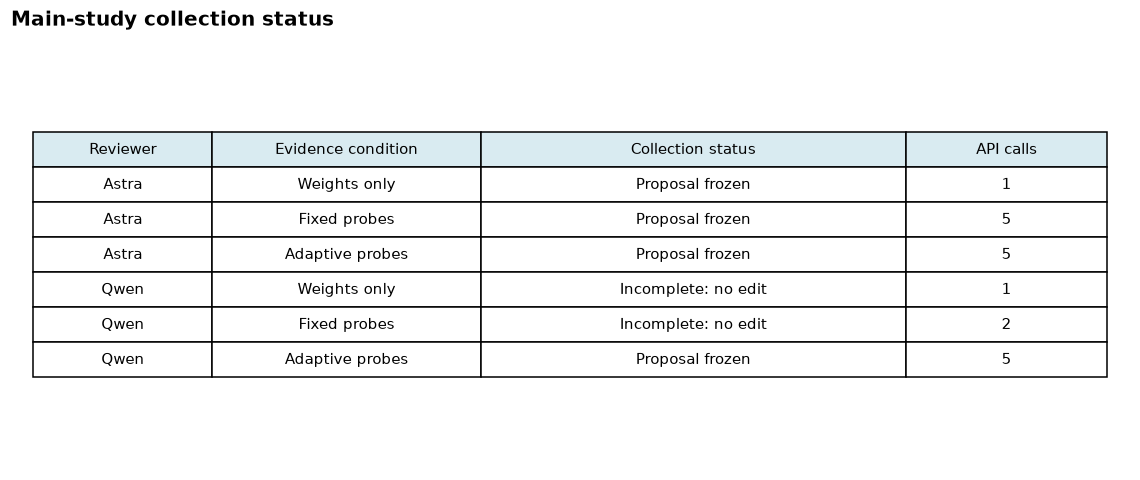

In [2]:
rows=[]
for item in plan['sessions']:
    sid=item['session_id']; session=ROOT/'private'/'review_sessions'/sid
    calls=ROOT/'private'/'remote_calls'/sid
    turns=list(calls.glob('turn-*.json')) if calls.is_dir() else []
    if (session/'repair_frozen.json').exists(): state='Proposal frozen'
    elif (session/'session_issue.json').exists(): state='Incomplete: no edit'
    elif turns: state='In progress / unresolved'
    else: state='Not started'
    label='Astra' if item['reviewer']=='gpt-6.2-astra' else 'Qwen'
    condition={'weights_only':'Weights only','fixed_probes':'Fixed probes','adaptive_probes':'Adaptive probes'}[item['condition']]
    rows.append([label,condition,state,str(len(turns))])
fig,ax=plt.subplots(figsize=(10.5,4.5)); ax.axis('off')
table=ax.table(cellText=rows,colLabels=['Reviewer','Evidence condition','Collection status','API calls'],
               cellLoc='center',loc='center',colColours=['#d9ebf1']*4,colWidths=[.16,.24,.38,.18])
table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1,1.7)
ax.set_title('Main-study collection status',loc='left',pad=10)
fig.tight_layout(); save(fig,'27_main_collection_status'); plt.show()
if report is None:
    print('No main-study accuracy scores are available: the cohort has not been frozen and evaluated.')

## 2. Held-out results

When collection is complete, the operator will freeze all valid proposals, explicitly record missing sessions, and run the held-out evaluator. This notebook will then read its saved aggregate result; it does not load the final examples or trigger evaluation itself.

A session that failed to produce an edit remains missing. An invalid response should not be converted into an invented proposal or silently excluded.

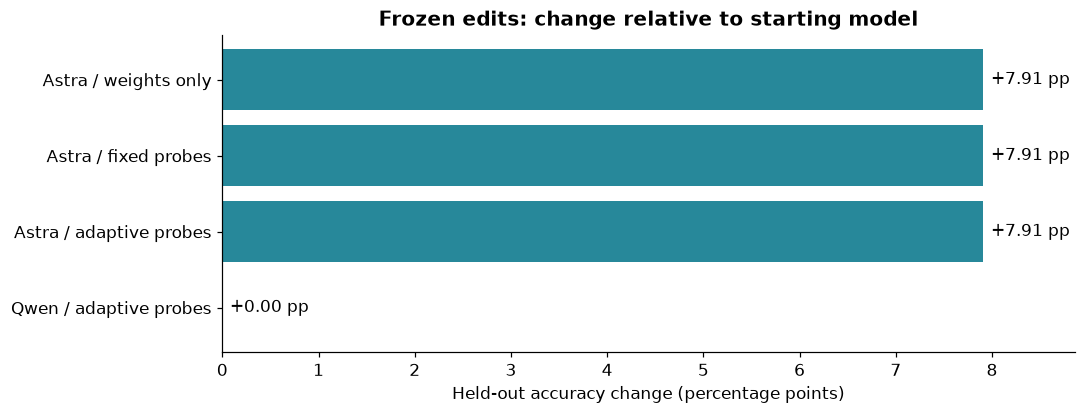

Held-out sample count: 4096
Missing: Qwen/Qwen3.8-27B weights_only — The weights-only reviewer requested probes rather than returning the required final edit. No probes were supplied and no scientific-content repair was attempted.
Missing: Qwen/Qwen3.8-27B fixed_probes — After the first fixed-probe batch the reviewer requested an adaptive input batch instead of replying READY, so the fixed-probe protocol could not continue.


In [3]:
if report is None:
    print('PENDING — no cohort freeze or held-out evaluation has been run.')
else:
    completed=[row for row in report['sessions'] if row['status']=='frozen']
    missing=[row for row in report['sessions'] if row['status']!='frozen']
    labels=[('Astra' if row['reviewer']=='gpt-6.2-astra' else 'Qwen')+' / '+row['condition'].replace('_',' ') for row in completed]
    fig,ax=plt.subplots(figsize=(10,max(3,0.6*len(completed)+1.5)))
    changes=[row['accuracy_change']*100 for row in completed]
    ax.barh(np.arange(len(labels)),changes,color=['#27889a' if x>=0 else '#d47743' for x in changes])
    ax.set(yticks=np.arange(len(labels)),yticklabels=labels,xlabel='Held-out accuracy change (percentage points)',title='Frozen edits: change relative to starting model')
    ax.axvline(0,color='#536a74',lw=1); ax.invert_yaxis()
    for i,value in enumerate(changes): ax.annotate(f'{value:+.2f} pp', (value,i), xytext=(5,0), textcoords='offset points', va='center')
    ax.margins(x=.12)
    fig.tight_layout(); save(fig,'28_main_accuracy_changes'); plt.show()
    print('Held-out sample count:',report['sample_count'])
    for row in missing: print('Missing:',row['reviewer'],row['condition'],'—',row.get('reason','not available'))

## 3. Interpretation boundaries

The calibration repair was a deliberately constructed case. The main study tests the learned checkpoint, but a single model and small number of sessions support only a narrow case study. A valid model-versus-model or fixed-versus-adaptive comparison requires the relevant sessions to be completed under the common protocol.

Before accessing held-out outcomes, end collection, preserve raw responses and missing-session reasons, and freeze the full planned cohort. Missing sessions limit the comparisons that can be drawn.

## 4. What each edit changed

Each reviewer could multiply one scalar, row, or column of the original network by a chosen factor. The table shows the proposal alongside held-out accuracy before and after that edit. Positive change means the edit helped on this sample; negative change means it made the model worse. An incomplete session is not an estimate of zero improvement.

In [4]:
if report is not None:
    from IPython.display import display, Markdown
    import pandas as pd
    detail=[]
    for row in report['sessions']:
        sid=row['session_id']; session=ROOT/'private/review_sessions'/sid
        entry={'Reviewer': 'Astra' if row['reviewer']=='gpt-6.2-astra' else 'Qwen',
               'Condition': row['condition'].replace('_',' '), 'Status': row['status'],
               'Before %': None, 'After %': None, 'Change (pp)': None, 'Edit': '—'}
        if row['status']=='frozen':
            proposal=json.loads((session/'repair_frozen.json').read_text())
            edit=proposal['edit']
            entry.update({'Before %':round(row['before']['accuracy']*100,2), 'After %':round(row['after']['accuracy']*100,2),
                          'Change (pp)':round(row['accuracy_change']*100,2),
                          'Edit':f"{edit['parameter']} {edit['index']} × {edit['scale']}"})
        detail.append(entry)
    display(pd.DataFrame(detail))

,Reviewer,Condition,Status,Before %,After %,Change (pp),Edit
0,Astra,weights only,frozen,91.85,99.76,7.91,"fc2.weight [None, 5] × 2"
1,Astra,fixed probes,frozen,91.85,99.76,7.91,"fc2.weight [None, 5] × 2"
2,Astra,adaptive probes,frozen,91.85,99.76,7.91,"fc2.weight [None, 5] × 2"
3,Qwen,weights only,missing,NaN,NaN,NaN,—
4,Qwen,fixed probes,missing,NaN,NaN,NaN,—
5,Qwen,adaptive probes,frozen,91.85,91.85,0.00,"fc1.weight [None, 3] × 0.0"


## 5. Where did the model improve or regress?

The four quadrants group examples by the signs of the first two coordinates. The bars show the change in accuracy within each group, using the same held-out examples before and after every edit. Group sizes differ slightly, so the overall change is not exactly the unweighted average of the bars.

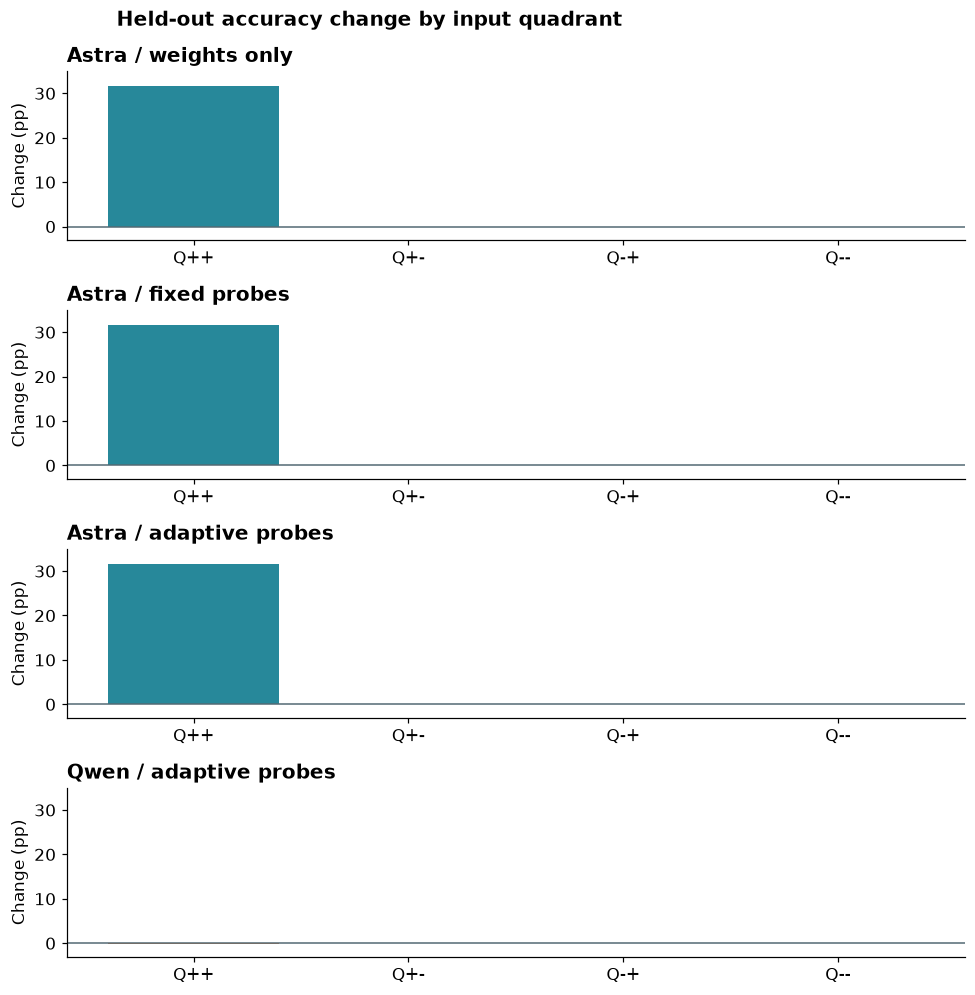

In [5]:
if report is not None:
    completed=[r for r in report['sessions'] if r['status']=='frozen']
    quadrants=['Q++','Q+-','Q-+','Q--']
    fig, axes=plt.subplots(len(completed),1,figsize=(9,max(2.5,2.3*len(completed))),squeeze=False)
    for ax,row in zip(axes[:,0],completed):
        changes=[100*(row['after']['quadrants'][q]['accuracy']-row['before']['quadrants'][q]['accuracy']) for q in quadrants]
        label=('Astra' if row['reviewer']=='gpt-6.2-astra' else 'Qwen')+' / '+row['condition'].replace('_',' ')
        ax.bar(quadrants,changes,color=['#27889a' if v>=0 else '#d47743' for v in changes]); ax.axhline(0,color='#536a74',lw=1)
        ax.set_ylabel('Change (pp)'); ax.set_title(label,loc='left')
    for ax in axes[:,0]: ax.set_ylim(-3, 35)  # Common scale makes conditions comparable.
    fig.suptitle('Held-out accuracy change by input quadrant',x=.125,ha='left',fontweight='bold')
    fig.tight_layout(); save(fig,'29_main_quadrant_changes'); plt.show()

## 6. Reading this as evidence

The no-probe condition shows what a reviewer proposed from the weights and task description alone. Fixed probes add the same preset examples; adaptive probes let the reviewer choose examples after seeing earlier logits. Each condition gets a separate conversation. The result measures one edit on one learned checkpoint, not the general ability of either model. Missing or invalid proposals limit which comparisons can be made.

A successful edit is an observed improvement on this held-out sample, not proof that the reviewer's explanation is correct or that probing caused the gain. Likewise, a regression is informative but does not identify a universal failure of a reviewer.

## 7. What the reviewers predicted

The following statements are the reviewers’ own explanations and expectations, shown alongside observed accuracy changes. They are hypotheses, not verified descriptions of the network. A proposal may improve accuracy even when parts of its explanation are incorrect.

In [6]:
if report is not None:
    from IPython.display import display, Markdown
    for row in report['sessions']:
        if row['status'] != 'frozen':
            continue
        sid=row['session_id']; folder=ROOT/'private/review_sessions'/sid
        frozen=json.loads((folder/'repair_frozen.json').read_text())
        filename='format_repair.txt' if frozen['format_repair_used'] else 'original.txt'
        proposal=json.loads((ROOT/'responses/raw'/sid/filename).read_text())
        reviewer='Astra' if row['reviewer']=='gpt-6.2-astra' else 'Qwen'
        display(Markdown(f"### {reviewer} · {row['condition'].replace('_',' ')}"))
        print('Reviewer hypothesis:', proposal['hypothesis'])
        print('Expected effect:', proposal['expected_effect'])
        print(f"Observed held-out accuracy change: {row['accuracy_change']*100:+.2f} percentage points\n")

### Astra · weights only

Reviewer hypothesis: The model underpredicts class 1 in the positive-positive quadrant. First-layer unit 5 detects a positive sum, but its signal into the second layer is too weak relative to the difference detectors: with nuisance inputs zero, (1, 0.1) and (0.1, 1) both yield negative logits.
Expected effect: Doubling unit 5's contribution makes both example logits positive and leaves every prediction unchanged where unit 5 is inactive. The main regression risk is a false positive on or just across a positive coordinate axis, where unit 5 can still be strongly active.
Observed held-out accuracy change: +7.91 percentage points



### Astra · fixed probes

Reviewer hypothesis: When both inputs are positive but unequal, the x0+x1 signal from first-layer unit 5 can be outweighed by difference-sensitive units. This occurs in both orderings: (0.246, 0.912) scored −10.37 and (0.550, 0.183) scored −1.41.
Expected effect: Doubling unit 5’s outgoing weights should recover missed positive pairs while leaving logits exactly unchanged wherever unit 5 is inactive. The main regression risk is a false positive on or just across an axis when the other input is positive.
Observed held-out accuracy change: +7.91 percentage points



### Astra · adaptive probes

Reviewer hypothesis: First-layer unit 5 provides too little positive-sum evidence: both (0.8,0.2) and (0.2,0.8) were false negatives. Probes that approximately doubled its activation relative to positive-axis inputs, while nearly preserving the sign-difference features, brought the logits close to zero on both sides.
Expected effect: Doubling unit 5's downstream contribution should recover positive-positive inputs near either axis while leaving logits exactly unchanged wherever unit 5 is inactive. Some axis or near-axis opposite-sign inputs may become false positives, especially as nuisance coordinates vary.
Observed held-out accuracy change: +7.91 percentage points



### Qwen · adaptive probes

Reviewer hypothesis: Small positive same-sign inputs with positive nuisance x3 are misclassified as class 0: [0.01, 0.01, 1, 1] gave -2.53 and [0.02, 0.02, 1, 1] gave -1.28, while [0.02, 0.02, 1, 0] and [0.02, 0.02, 0, 1] were nonnegative and [0.04, 0.04, 1, 1] was positive. Since x3 is intended to be nuisance, zeroing its input column should remove the harmful nuisance activation without changing the intended x0/x1 sign logic.
Expected effect: Zeroing fc1.weight column 3 removes x3 influence, especially through the nuisance-sensitive first-layer rows. This should flip the small positive same-sign false negatives with x3=1 to positive logits and reduce nuisance-driven boundary errors. Possible regression: some class-0 opposite-sign or zero-boundary cases where x3 helped activate negative second-layer units may become slightly less negative, but the probed strong opposite-sign and zero cases have large margins; residual x2-only zero-boundary false positives remain the main uncertainty.
